# Fitting a 1D population receptive field model to fMRI data from a numerosity experiment

This examples shows how to fit a population receptive field (pRF) model to blood oxygenation level-dependent (BOLD) functional magnetic resonance imaging
(fMRI) data.

A pRF model maps neural activity in a brain region of interest (ROI; e.g., V1 in the human visual cortex)
to an experimental stimulus. Here, we use numerosity (e.g., the number of circles displayed on a screen) as an example,
where the pRF defines a distribution in numerosity space that stimulates activity in the region of interest.
Because the numerosity space is one-dimensional, the pRF model also has one dimension.

Because prfmodel uses Keras for model fitting, we need to make sure that a backend is installed before we begin.
In this example, we use the TensorFlow backend.

In [1]:
import os
from importlib.util import find_spec
import pandas as pd

# Set keras backend to 'tensorflow' (this is normally the default)
os.environ["KERAS_BACKEND"] = "tensorflow"
# Print parameter DataFrames with three decimals
pd.set_option("display.precision", 3)

if find_spec("tensorflow") is None:
    msg = 'Could not find the tensorflow package. Please install it with: pip install "prfmodel[tensorflow]"'
    raise ImportError(msg)

## Loading the stimulus

In this example, we use a public dataset by [Hendrikx et al. (2024)](https://doi.org/10.1016/j.neuroimage.2024.120515) that is available on [Fig Share](https://doi.org/10.6084/m9.figshare.24126663).

The numerosity stimulus that belongs to this dataset is already included in the package and can be loaded with {py:func}`prfmodel.examples.load_1d_prf_lognumerosity_stimulus`. It is also available as the `stimulus` attribute of the loaded dataset.

In [2]:
from prfmodel.examples import load_1d_prf_lognumerosity_stimulus

stimulus = load_1d_prf_lognumerosity_stimulus()
print(stimulus)

I0000 00:00:1793465063.123558    5560 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793465063.124644    5560 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793465063.297837    5560 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793465065.311027    5560 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

PRFStimulus(design=array[182, 8], grid=array[8, 1], frame_duration=2.1, dimension_labels=['log_numerosity'])


The stimulus design is a matrix with shape `(num_frames, num_coordinates)` that one-hot encodes which numerosity index is active at which time frame. The stimulus grid maps each numerosity index to its corresponding log numerosity value. There are eight unique numerosities. We can look at them on the natural scale.

In [3]:
import numpy as np

unique_log_numerosities = stimulus.grid.squeeze()
unique_numerosities = np.round(np.exp(unique_log_numerosities))

unique_numerosities

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7., 20.])

We can also plot the stimulus design with {py:func}`prfmodel.plotting.plot_1d_prf_stimulus` to see how numerosity
changes over time.

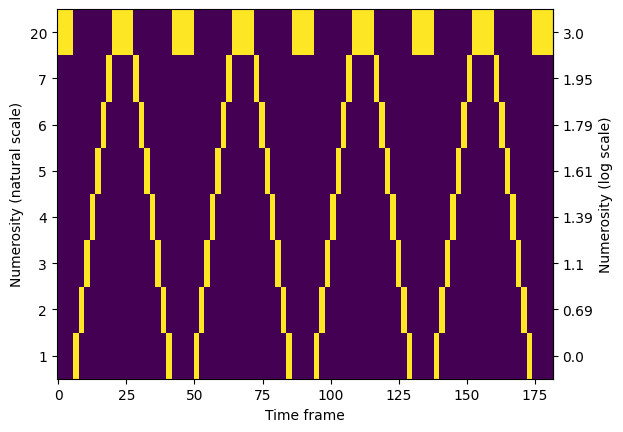

In [4]:
from prfmodel.plotting import plot_1d_prf_stimulus

plot_1d_prf_stimulus(
    stimulus,
    tick_labels=unique_numerosities.astype(int),
    secondary_tick_labels=np.round(unique_log_numerosities, 2),
    ylabel="Numerosity (natural scale)",
    secondary_ylabel="Numerosity (log scale)",
);

We can see that the design contains ascending and descending numerosity sequences from one to seven that are interleaved with sequences of the "baseline" numerosity 20. The ascend-descend cycle is repeated four times. Before the first cycle, there is a short baseline interval that was shown before the fMRI recording started (pre-scan interval). We will take both the cycles and the pre-scan interval into account when fitting the pRF model.

## Loading the BOLD response

Now that we have our numerosity stimulus, we load the fMRI response data from a single subject. The dataset contains volumetric BOLD responses for several stimulus conditions, as well as a mapping between voxels and vertices on the cortical surface.

### Stimulus conditions

Changing numerosity can also affect other visual properties of the stimulus. Consequently, a neural response that appears to be selective for numerosity might instead reflect one of these correlated visual features.

To account for this, the dataset contains responses for four stimulus conditions, each controlling a different visual property:

- **Area (constant area):** The total surface area of all dots remains constant across numerosities.
- **Size (constant dot size):** The size of each individual dot remains constant.
- **Dens (high density):** The same dots as in the constant-area condition are presented within a smaller region, resulting in a higher density.
- **Circ (constant circumference):** The total circumference of all dots remains constant across numerosities.

By fitting the pRF model separately to each condition, we can investigate whether the spatial organization of preferred numerosity is consistent across different stimulus configurations.

We first use the **Average** condition, which combines the responses across the four individual conditions. This provides an overall estimate of numerosity preference. Later, we fit the model separately to each condition to compare their spatial organization.

The stimulus sequence consists of four repetitions of a 44-frame cycle, preceded by a six-frame pre-scan interval (182 frames in total). During preprocessing, the pre-scan frames are excluded and the four repetitions are averaged, resulting in a 44-frame response time course for each voxel.

In [5]:
from pathlib import Path
import pickle

# Find the workshop repository root
PROJECT_ROOT = Path.cwd()

data_path = PROJECT_ROOT / "data" / "fmri_full_grid_dataset.pkl"

with data_path.open("rb") as f:
    dataset = pickle.load(f)

# Inspect volumetric response tables
print("Available conditions:", list(dataset.responses))

for condition, response in dataset.responses.items():
    print(f"{condition} shape: {response.shape}")
   


Available conditions: ['Area', 'Size', 'Dens', 'Circ', 'Average']
Area shape: (672999, 44)
Size shape: (672999, 44)
Dens shape: (672999, 44)
Circ shape: (672999, 44)
Average shape: (672999, 44)


The BOLD responses are initially stored as volumetric data, with one time course per voxel. We start by selecting the Average condition and retaining only voxels marked as valid for this condition. Validity is determined by the values of the timeseries. As some voxels fall outside the area included in the scan these were given a value of 0 at that timepoint. Voxels containing 0's in their timeseries were therefor marked as invalid.

In [6]:
# Select the average response table
average_response = dataset.responses["Average"]
average_valid = dataset.valid["Average"]

# Keep only voxels valid for the average condition
average_response_valid = average_response[average_valid]
print(average_response_valid.shape)

(390217, 44)


Before fitting the model, we convert the raw responses into percent signal change (PSC). We do this separately for each voxel by dividing its time course by its mean signal and expressing the result as a percentage change from that mean.

This makes the response amplitudes comparable across voxels and gives us a signal centred approximately around zero.

In [7]:
def convert_psc(response_raw: np.ndarray) -> np.ndarray:
    """Convert raw responses into percent signal change per voxel."""
    response_mean = response_raw.mean(axis=1, keepdims=True)

    with np.errstate(divide="ignore", invalid="ignore"):
        response_psc = (response_raw / response_mean - 1.0) * 100.0

    return response_psc


# Convert the valid response table to PSC
average_response_psc = convert_psc(average_response_valid)
print(average_response_psc.shape)


(390217, 44)


We next remove slow trends from the measured responses using a discrete cosine transform (DCT) basis. We construct cosine functions with frequencies determined by `N_DCT` and fit them to each voxel's time course using a pseudoinverse. The fitted trends are then subtracted from the original responses.

Detrending helps remove slow signal fluctuations that are not part of the stimulus-driven response. We use the same detrending approach for the model predictions later, so that the measured and predicted responses are treated consistently.

In [8]:
N_DCT = 0.5

n_timepoints = average_response_psc.shape[1]

# Construct cosine trend basis
time = np.linspace(0, 2 * np.pi, n_timepoints)
frequencies = np.arange(0, N_DCT + 0.25, 0.5)
trends = np.cos(np.outer(time, frequencies))

# Fit and remove trends
pinv_trends = np.linalg.pinv(trends)
beta = pinv_trends @ average_response_psc.T
fitted_trend = (trends @ beta).T

average_response_detrended = (average_response_psc - fitted_trend)

print("Detrended response shape:", average_response_detrended.shape)

Detrended response shape: (390217, 44)


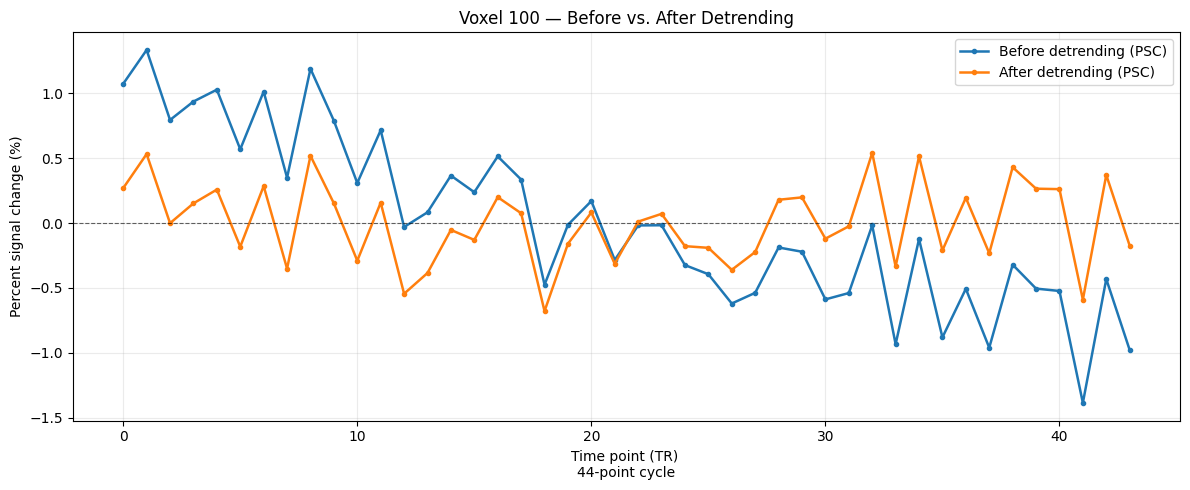

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Select a valid voxel to inspect
voxel_idx = 100

before = average_response_psc[voxel_idx]
after = average_response_detrended[voxel_idx]

timepoints = np.arange(len(before))

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    timepoints,
    before,
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="Before detrending (PSC)",
)

ax.plot(
    timepoints,
    after,
    marker="o",
    markersize=3,
    linewidth=1.8,
    label="After detrending (PSC)",
)

ax.axhline(0, color="black", linewidth=0.8, linestyle="--", alpha=0.6)

ax.set_title(f"Voxel {voxel_idx} — Before vs. After Detrending")
ax.set_xlabel("Time point (TR) \n44-point cycle")
ax.set_ylabel("Percent signal change (%)")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


The plot clearly shows how detrending removes the slow downward drift in the measured signal. This gradual change is not necessarily related to the stimulus, so removing it helps isolate the stimulus-related fluctuations in the BOLD response.

## Projecting the responses onto the cortical surface

Our analysis focuses on cortical surface vertices rather than individual volume voxels. We therefore project the detrended voxel responses onto the surface using the voxel-to-vertex mapping supplied with the dataset. This assignment was created using nearest neighbours projection for all valid voxels in the dataset.

For each surface vertex, we identify the voxels assigned to it, retain those with valid responses, and average their time courses. This gives us one response time course per surface vertex.

Vertices without any valid contributing voxels are excluded. We keep track of the original surface vertex indices so that the responses can later be matched to their anatomical ROI labels and geodesic distances.

In [10]:

#Load the dataset's voxel-to-vertex mapping
vertex_voxel_offsets = dataset.method2_vertex_voxel_offsets
vertex_voxel_rows = dataset.method2_vertex_voxel_rows

n_vertices = len(dataset.vertex_coordinates)
n_timepoints = average_response_detrended.shape[1]

# Map original voxel indices to rows in the filtered response array
original_to_valid = np.full(len(average_valid), -1, dtype=int)
original_to_valid[np.flatnonzero(average_valid)] = np.arange(average_valid.sum())

# Average valid voxel responses for each vertex and create vertex validity
vertex_response = np.zeros((n_vertices, n_timepoints))
vertex_valid = np.zeros(n_vertices, dtype=bool)

for v in range(n_vertices):
    rows = vertex_voxel_rows[vertex_voxel_offsets[v]:vertex_voxel_offsets[v + 1]]
    rows = original_to_valid[rows]
    rows = rows[rows >= 0]

    if len(rows):
        vertex_response[v] = average_response_detrended[rows].mean(axis=0)
        vertex_valid[v] = True



print(f"Vertex response: {vertex_response.shape}")
print(f"Valid vertices: {vertex_valid.sum():,} / {n_vertices:,}")

Vertex response: (311542, 44)
Valid vertices: 196,094 / 311,542


In [11]:
#Mask the response table to keep only valid vertices and get their indices
vertex_response = vertex_response[vertex_valid]
valid_vertex_indices = np.flatnonzero(vertex_valid)

After projecting the responses onto the cortical surface, we obtain one 44-frame time course per valid surface vertex. We can now associate these vertices with their anatomical ROI labels.

In [12]:
# Select ROI labels for surface vertices
roi_index = dataset.vertex_roi_index
roi_index_valid = roi_index[vertex_valid]
roi_index_valid.shape

(196094,)

We can look at the unique ROI indices.

In [13]:
np.unique_counts(roi_index_valid)

UniqueCountsResult(values=array([-1,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12], dtype=int32), counts=array([184255,   1249,    474,   1226,   1154,    639,    484,   1653,
          190,   2346,    875,    774,    775]))

The mapping between ROI indices and labels comes with the dataset as well.

In [14]:
roi_mapping = dataset.roi_names
roi_mapping

{1: 'lh_NumTO',
 2: 'lh_NumPO',
 3: 'lh_NumPC1',
 4: 'lh_NumPC2',
 5: 'lh_NumPC3',
 6: 'lh_NumF',
 7: 'rh_NumTO',
 8: 'rh_NumPO',
 9: 'rh_NumPC1',
 10: 'rh_NumPC2',
 11: 'rh_NumPC3',
 12: 'rh_NumF'}

The ROI labels start with their corresponding hemisphere and "Num" to indicate that they refer to a numerosity map. NTO and NPO are
occipital regions; the NPCS are regions in parietal cortex; NF is located around the
frontal sulcus (see Hendrikx et al., 2024, for details).

## Inspecting the data

Before we model the BOLD response, we look at the timecourses and inspect the quality of the data. To do this we select a subset of vertices and plot their BOLD response over time. Note that the unit of time frames is repetition time (TR) which is
2.1 seconds for this dataset.

In [15]:
import plotly.io as pio
import plotly.express as px

pio.renderers.default = "notebook_connected"  # Requires internet connection to work
pio.templates.default = "simple_white"

#Create a response table for the chosen ROI (ROI index 1 corresponds to lh_NumTO)
roi_mask = roi_index_valid == 1
roi_response = vertex_response[roi_mask]

fig = px.line(
    roi_response[::10, :].T,
    animation_frame="variable",
    range_x=(0, 44),
    range_y=(-1.5, 1.5),
    labels={
        "index": "Time frame (in TR)",
        "value": "BOLD response",
        "variable": "Vertex",
    },
    title="Vertex time courses"
)

fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 900
fig.layout.updatemenus[0].buttons[0].args[1]["transition"]["duration"] = 400

fig.update_layout(showlegend=False, height=450)
fig.show()

For several vertices, we can see response patterns that approximately match the ascend-descend cycle of the numerosity stimulus. The goal of our pRF model is to predict these cycles as closely as possible. By comparing how similar the pRF model predictions are to the observed timecourses, we can identify vertices and areas of the brain that respond to our visual stimulus. This allows us to create a stimulus-specific pRF map of the brain.

## Defining the pRF model

Now that we have our BOLD response data and stimulus in place, we can create a pRF model to *predict* a response to this stimulus. We use the canonical 1D pRF model proposed by Harvey et al. (2013): It assumes that the stimulus (numerosity) elicits a response that follows a
Gaussian shape in one-dimensional log-numerosity space. This response is convolved with an impulse response
that follows the shape of the hemodynamic response in the brain. Finally, a baseline and amplitude parameter shift and scale
our predicted response to match the observed BOLD response.

The {py:class}`prfmodel.models.prf.Gaussian1DPRFModel` class performs all these steps to make a combined prediction. Each time frame is one TR of 2.1 seconds, which the example stimulus stores as its `frame_duration`. The pRF model samples its impulse response at this frame duration, so the predicted response has the same sampling rate as the observed timecourses (see also the section [](../../important_details.md)).

In [16]:
from prfmodel.impulse import DerivativeTwoGammaImpulse
from prfmodel.models.prf import Gaussian1DPRFModel

# Repetition time (TR) from the stimulus
print(stimulus.frame_duration)

# Create the impulse model
impulse_model = DerivativeTwoGammaImpulse()

2.1


We can visualize the predicted impulse response. The two-gamma parameters (`delay`, `dispersion`, `undershoot`,
`u_dispersion`, `ratio`) default to the Glover HRF parameter set
(see {py:func}`~prfmodel.impulse.defaults.default_two_gamma_impulse_glover_hrf`), so we only need to set `weight_deriv`. This parameter weights the temporal derivative of the two-gamma response and absorbs small differences in hemodynamic latency between vertices. Negative values shift the response earlier in time, positive values later. We start from `-0.5` and let the fitter refine it per vertex further below. On its own, the impulse model does not know the stimulus, so we sample it at the frame duration of the stimulus with {py:meth}`~prfmodel.impulse.base.BaseImpulse.at_resolution` before plotting.

In [17]:
import pandas as pd

# Only weight_deriv is set; the two-gamma parameters use the model's default Glover HRF values
impulse_default_params = pd.DataFrame({"weight_deriv": [-0.5]})

# Predict impulse response (two-gamma parameters use the default Glover HRF values)
impulse_response = np.asarray(impulse_model.at_resolution(stimulus.frame_duration)(impulse_default_params))

fig = px.line(
    pd.DataFrame({"Time frame (in TR)": np.arange(impulse_response.shape[1]), "Impulse response": impulse_response[0]}),
    x="Time frame (in TR)",
    y="Impulse response",
    title="Predicted impulse response"
)

fig.update_layout(height=450)
fig.show()

E0000 00:00:1793465073.075368    5560 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


We insert the impulse model into the {py:class}`~prfmodel.models.prf.Gaussian1DPRFModel` that makes combined model predictions.

In [18]:
# Define pRF model with the impulse response submodel
prf_model = Gaussian1DPRFModel(impulse_model=impulse_model)

As mentioned above, the numerosity stimulus includes a pre-scan interval of six time frames during which no BOLD response was recorded. However, the subject has still seen this interval, so it can influence the response recorded afterwards.

We therefore retain the pre-scan interval when generating model predictions, but remove its first six frames before comparing predictions with the measured responses. The remaining 176 frames contain four repetitions of the 44-frame stimulus cycle.

We average these four cycles to obtain a single 44-frame predicted response. Finally, we detrend the averaged prediction using the same cosine basis as for the measured responses. This ensures that the model predictions and measured responses have matching time dimensions and undergo consistent preprocessing.

We define a set of starting parameters to generate predictions with our pRF model. Specifically, we predict the model response for each unique numerosity value in the stimulus. Each prediction represents the response over one 44-frame stimulus cycle, following the removal of the pre-scan interval, averaging of repeated cycles and detrending.

In [19]:
import tensorflow as tf
from typing import Callable
from prfmodel.stimuli import PRFStimulus
from prfmodel.typing import Tensor

def average_cycles_and_detrend(
    fn: Callable,
    num_prescan_frames: int = 6,
    cycle_length: int = 44,
    num_cycles: int = 4,
    n_dct: float = 0.5
    ) -> Callable:
    """Average repeated stimulus cycles and detrend the predictions."""

    # Use the same cosine basis as the measured-response detrending
    time = np.linspace(0, 2 * np.pi, cycle_length)
    frequencies = np.arange(0, n_dct + 0.25, 0.5)
    trends = np.cos(np.outer(time, frequencies))

    # Compute pseudoinverse once
    pinv_trends = np.linalg.pinv(trends)

    def wrapper(stimulus: PRFStimulus, parameters: pd.DataFrame, *args, **kwargs) -> Tensor:
        predictions = fn(stimulus, parameters, *args, **kwargs)

        # 1. Remove prescan frames
        predictions = predictions[:, num_prescan_frames:]

        # 2. Average repeated stimulus cycles
        predictions = tf.reshape(predictions, (tf.shape(predictions)[0], num_cycles, cycle_length))
        predictions = tf.reduce_mean(predictions, axis=1)

        # 3. Detrend averaged predictions
        trends_tf = tf.cast(trends, predictions.dtype)
        pinv_trends_tf = tf.cast(pinv_trends, predictions.dtype)

        beta = tf.matmul(predictions, pinv_trends_tf, transpose_b=True)
        fitted_trend = tf.matmul(beta, trends_tf, transpose_b=True)

        predictions = predictions - fitted_trend

        return predictions

    return wrapper

prf_model.call = average_cycles_and_detrend(prf_model.call)


Before fitting the model to the measured responses, we can visualize its predicted response for different preferred numerosities. The animation shows how the predicted response changes over time for each preferred numerosity.

In [20]:
# Combine pRF starting parameters with impulse response default parameters
num_unique_numerosities = len(unique_log_numerosities)

start_params = pd.DataFrame(
    {
        "mu": unique_log_numerosities,
        "sigma": [1.0] * num_unique_numerosities,
        "baseline": [0.0] * num_unique_numerosities,
        "amplitude": [1.0] * num_unique_numerosities,
        "weight_deriv": [-0.5] * num_unique_numerosities,
    }
)

# Make prediction with pRF model
simulated_response = np.asarray(prf_model(stimulus, start_params))

# Convert to data frame for plotting
simulated_response_df = pd.DataFrame(simulated_response.T, columns=unique_numerosities.astype(int))

fig = px.line(
    simulated_response_df,
    animation_frame="variable",
    range_x=(0, 44),
    labels={
        "index": "Time frame",
        "value": "Predicted neural response",
        "variable": "Numerosity (natural scale)",
    }
)

fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 900
fig.layout.updatemenus[0].buttons[0].args[1]["transition"]["duration"] = 400

fig.update_layout(showlegend=False, height=450)
fig.show()

## Fitting the pRF model

We now fit the pRF model to the detrended Average responses projected onto the cortical surface. Each valid vertex has its own response time course, and we estimate the pRF parameters separately for every vertex.

We use three stages of fitting. First, a grid search identifies promising values for the pRF centre (`mu`) and size (`sigma`). Next, least squares estimates the response `baseline` and `amplitude`. Finally, stochastic gradient descent (SGD) refines the parameter estimates.

The resulting parameters describe each vertex's preferred numerosity, pRF size, and response characteristics.

Let's start with the grid search by defining ranges of `mu` and `sigma` that we want to construct a grid of parameter values from. We create them from the stimulus with {py:func}`prfmodel.fitters.grid_values_1d_prf`.

For `baseline`, `amplitude`, and `weight_deriv`, we only provide a single value, so they stay constant across the entire grid. The two-gamma parameters of the impulse response model are omitted entirely: the model supplies them from its default Glover HRF parameter set. However, if we wanted to override these default parameters, we could also add ranges for them here.

In [21]:
from prfmodel.fitters import grid_values_1d_prf

param_ranges = grid_values_1d_prf(stimulus) | {
    # delay, dispersion, undershoot, u_dispersion, and ratio use the default Glover HRF parameters
    "weight_deriv": [-0.5],
    "baseline": [0.0],
    "amplitude": [1.0],
}

By default, the function creates 49 values for `mu` that span twice the range of the stimulus around its midpoint, and 50 log-spaced values for `sigma` that range from the smallest spacing between the stimulus coordinates to their full range. The grid search will evaluate all possible combinations of these values and return the combination that fits the observed data best. This results in a grid containing $49 \times 50 = 2450$ parameter combinations. This is still a relatively small grid, and we recommend specifying finer grids in practice.

Two properties of the stimulus bound what these ranges can achieve. First, the range of `mu` extends beyond the displayed numerosities, from about 0.2 to 90 on the natural scale. Estimates outside the displayed numerosities 1 to 7 (which includes the baseline numerosity 20) are only weakly constrained by the data, and we will exclude them when we analyze the pRF parameters. Extending the grid beyond the stimulus prevents vertices from accumulating at the edges of the grid.

Second, the stimulus samples log-numerosity space at only eight points. The closest two values are $\log(7) - \log(6) \approx 0.15$ apart. This spacing determines the smallest value of `sigma` in the grid. A pRF much narrower than this spacing responds to a single numerosity, regardless of how much smaller `sigma` becomes. Therefore, the lower end of the `sigma` range is not identifiable from these data, and estimates near the lower limit should be interpreted as "no wider than one stimulus level".

Let's construct the {py:class}`prfmodel.fitters.GridFitter` and perform the grid search. Note that we set `batch_size=20` to let the `GridFitter` evaluate 20 parameter combinations at the same time, which saves memory. By default, the `loss` (i.e., the metric to minimize between model predictions and data) is the negative correlation. This ignores differences in baseline and amplitude between model predictions and observed data. This means the data do not need to be demeaned or converted to percent signal change first, but it also means that `baseline` and `amplitude` cannot be estimated by the grid search itself. We fix them here and estimate them with least squares in the next step.

In [ ]:

from prfmodel.fitters import GridFitter

# Create grid fitter object
grid_fitter = GridFitter(
    model=prf_model,
    stimulus=stimulus,
    compile_step=True
)

# Run grid search on valid vertices using detrended PSC responses
grid_history, grid_params = grid_fitter.fit(
    data=vertex_response,
    parameter_values=param_ranges,
    batch_size=200
)

grid_params

Processing parameter grid:   0%|          | 0/13 [00:00<?, ?it/s]

,mu,sigma,weight_deriv,baseline,amplitude
0,2.372,0.700,-0.5,0.0,1.0
1,2.372,0.700,-0.5,0.0,1.0
2,1.623,0.196,-0.5,0.0,1.0
3,2.372,0.550,-0.5,0.0,1.0
4,-0.999,1.007,-0.5,0.0,1.0
...,...,...,...,...,...
196089,1.872,1.961,-0.5,0.0,1.0
196090,2.621,0.517,-0.5,0.0,1.0
196091,-1.498,2.996,-0.5,0.0,1.0
196092,-1.373,0.250,-0.5,0.0,1.0


We can see that the estimates for `mu` and `sigma` are one combination from our grid. In the second step, we also optimize the `amplitude` of the pRF model together with the `baseline` using least squares. The amplitude determines the scale of the model response, while the baseline accounts for an offset in the observed response. This adjusts the scale and offset of our model predictions to better match the observed data.

In [23]:
from prfmodel.fitters import LeastSquaresFitter

# Create least-squares fitter
ls_fitter = LeastSquaresFitter(model=prf_model, stimulus=stimulus)

# Refine grid-search parameters using detrended PSC responses
ls_history, ls_params = ls_fitter.fit(
    data=vertex_response,
    parameters=grid_params,
    slope_name="amplitude",
    intercept_name="baseline",
    batch_size=200
)

ls_params

Processing data batches:   0%|          | 0/981 [00:00<?, ?it/s]

,mu,sigma,weight_deriv,baseline,amplitude
0,2.372,0.700,-0.5,-2.597e-09,0.401
1,2.372,0.700,-0.5,-2.597e-09,0.401
2,1.623,0.196,-0.5,5.616e-10,0.060
3,2.372,0.550,-0.5,1.685e-09,0.320
4,-0.999,1.007,-0.5,-2.246e-09,0.818
...,...,...,...,...,...
196089,1.872,1.961,-0.5,8.424e-10,1.549
196090,2.621,0.517,-0.5,-1.123e-09,0.084
196091,-1.498,2.996,-0.5,1.123e-09,2.888
196092,-1.373,0.250,-0.5,1.685e-09,0.000


We can see that the amplitudes are different compared to the starting value (and our initial guess) for many vertices.

To finetune the parameter estimates with SGD, we use the {py:class}`~prfmodel.fitters.SGDFitter` with the
least-squares parameters as starting values. Because the size of the pRF `sigma` is a strictly positive parameter
(always > 0), we include an adapter with a log-transformation in the fitter. The adapter log-transforms `sigma` so that
the fitter can optimize it on an unconstrained scale, and transforms it back to the strictly positive scale before
model predictions are compared against the observed data.

By default, {py:class}`~prfmodel.fitters.SGDFitter` optimizes every parameter column it is given, so `weight_deriv` is refined per vertex here as well. This lets each vertex have a slightly different hemodynamic latency, but it also means that the shape of the impulse response is no longer fixed while `mu` and `sigma` are estimated. Pass `fixed_parameters=["weight_deriv"]` to `fit` to keep the impulse response identical across vertices instead.

In [24]:
from keras import ops
from prfmodel.fitters import SGDFitter
from prfmodel.fitters.adapter import Adapter, ParameterTransform

adapter = Adapter([
    ParameterTransform(
        ["sigma"],
        transform_fun=ops.log,
        inverse_fun=ops.exp
    )
])

sgd_fitter = SGDFitter(
    model=prf_model,
    stimulus=stimulus,
    adapter=adapter,
    compile_step=True
)

sgd_history, sgd_params = sgd_fitter.fit(
    data=vertex_response,
    init_parameters=ls_params
)

sgd_params

Processing data batches:   0%|          | 0/1 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/1000 [00:00<?, ?it/s]

,mu,sigma,weight_deriv,baseline,amplitude
0,2.358,0.696,-0.469,-6.625e-09,4.030e-01
1,2.358,0.696,-0.469,-6.625e-09,4.030e-01
2,1.637,0.196,-0.521,1.723e-09,5.978e-02
3,2.367,0.546,-0.453,1.876e-08,3.213e-01
4,-0.999,1.006,-0.498,-7.424e-09,8.176e-01
...,...,...,...,...,...
196089,1.884,1.961,-0.497,1.379e-09,1.549e+00
196090,2.618,0.517,-0.490,3.095e-08,8.415e-02
196091,-1.498,2.989,-0.582,1.127e-09,2.889e+00
196092,-1.373,0.250,-0.500,1.048e-07,1.354e-06


We can see that SGD has substantially changed parameter estimates for some vertices.

Now that the core pRF parameters and the auxiliary baseline and amplitude parameters are optimized, we can compare the model predictions against the observed responses.

To generate predictions for all fitted vertices, we wrap our `prf_model` in the {py:func}`prfmodel.utils.batched` modifier function. This changes the behavior of the model so that predictions are generated for batches of vertices sequentially. This saves memory at the expense of a small amount of additional runtime.

In [25]:
from prfmodel.utils import batched

prf_model_batched = batched(prf_model)
pred_response = np.asarray(prf_model_batched(stimulus, sgd_params, batch_size=100))

We can quantify how well the predictions align with the observed time courses using the R-squared metric, which we compute with {py:func}`prfmodel.utils.calculate_r_squared`. This metric indicates the proportion of variance in the observed data explained by our model predictions.

We calculate one R-squared value for each fitted vertex by comparing the predicted responses with the measured Average responses used during fitting. These scores therefore describe the in-sample model fit.

In [26]:
from prfmodel.utils import calculate_r_squared

# Calculate one R² score per fitted vertex
r_squared = calculate_r_squared(vertex_response, pred_response)

print("R² shape:", r_squared.shape)

R² shape: (196094,)


We can now inspect how well the model predictions match the observed BOLD responses for individual surface vertices. To do this, we select one ROI, lh_NumTO in this case, and extract the observed responses, model predictions, and fitted pRF parameters for its vertices.

We then sort the vertices by their R-squared values, from highest to lowest, and select every tenth vertex. This gives us a subsample of the best-fitting vertices to visualize without plotting every vertex in the ROI.

For each selected vertex, we plot the observed and predicted time courses alongside its R-squared value, pRF size (`sigma`), and preferred numerosity.

In [27]:
# Select ROI
roi_index = 1

roi_mask = roi_index_valid == roi_index
roi_name = roi_mapping[roi_index]

# Select ROI responses and fit parameters
vertex_response_roi = vertex_response[roi_mask]
pred_response_roi = pred_response[roi_mask]
r_squared_roi = r_squared[roi_mask]
sgd_params_roi = sgd_params.loc[roi_mask].reset_index(drop=True)

# Select the 10 best-fitting vertices
n_best = 10
best_vertices = np.argsort(r_squared_roi)[::-1][:n_best]

# Extract responses and fit parameters
response_best = vertex_response_roi[best_vertices]
prediction_best = pred_response_roi[best_vertices]

r_squared_best = r_squared_roi[best_vertices]
sigma_best = sgd_params_roi["sigma"].to_numpy()[best_vertices]
mu_best = np.exp(sgd_params_roi["mu"].to_numpy()[best_vertices])

In [28]:
from helpers import plot_vertex_fits

plot_vertex_fits(
    observed=response_best,
    predicted=prediction_best,
    r_squared=r_squared_best,
    sigma=sigma_best,
    preferred_numerosity=mu_best,
    roi_name = roi_name
)

We sort the vertices by their R-squared values, from highest to lowest, and select the ten best-fitting vertices. This allows us to inspect examples where the model captures the observed time courses particularly well.

## Analyzing the pRF results

To analyze and interpret the pRF parameters, we will zoom in on vertices with out-of-sample R-squared > 0.2 which is roughly 49% of the valid vertices (note that this threshold is somewhat arbitrary).

In [50]:
# Create mask for vertices above R-squared threshold
is_above_threshold = r_squared > 0.2

# Compute proportion of vertices above threshold
is_above_threshold.mean()

np.float64(0.48664416045366)

We further exclude vertices whose preferred numerosity falls outside the displayed numerosities 1 to 7, excluding 20
because it served as the baseline. We also remove vertices whose pRF size (`sigma`) approaches the span of the
log-numerosity space ($\log(20) \approx 3.0$), because such a wide Gaussian predicts an almost flat line, which leaves
`mu` unidentifiable. Note that SGD optimizes `sigma` on an unconstrained log scale, so the estimates are no longer
capped by the grid we defined above.

In [51]:
is_valid = (
    is_above_threshold
    & (np.exp(sgd_params["mu"]).between(1, 7))
    & (sgd_params["sigma"] < 2.8)
)
is_valid.mean()

np.float64(0.21993533713423155)

We add the ROI labels to each vertex in the parameters dataframe and transform `mu` into preferred numerosity.

In [52]:
final_params = sgd_params.copy()

# Attach ROI names to vertices
final_params["roi"] = [
    roi_mapping.get(int(idx), np.nan)
    for idx in roi_index_valid
]

# Convert preferred numerosity from log scale
final_params["numerosity"] = np.exp(final_params["mu"])

# Keep vertices with valid fitted parameters and ROI labels
params_valid = final_params.loc[is_valid].dropna(subset=["roi"]).copy()

# Preserve anatomical ROI order
roi_order = list(roi_mapping.values())

params_valid["roi"] = pd.Categorical(
    params_valid["roi"],
    categories=roi_order,
    ordered=True
)

Now, we can compare the average preferred numerosity between ROIs. We also keep the number of surviving
vertices per ROI, because it varies by an order of magnitude and tells us how many data points go into each average.

In [53]:
params_agg_roi = params_valid.groupby("roi", observed=False)[["numerosity", "sigma"]].agg(
    ["mean", "std", "count"]
)

params_agg_roi.round(2)

numerosity             sigma            
                mean   std count  mean   std count
roi                                               
lh_NumTO        3.79  1.74   426  1.06  0.54   426
lh_NumPO        3.47  1.33   198  1.14  0.60   198
lh_NumPC1       2.47  0.90   718  1.00  0.48   718
lh_NumPC2       2.73  0.96   680  1.11  0.41   680
lh_NumPC3       3.31  1.27   340  1.10  0.55   340
lh_NumF         2.44  0.86   354  0.88  0.33   354
rh_NumTO        4.60  1.53   650  0.91  0.47   650
rh_NumPO        4.12  1.42    99  1.08  0.64    99
rh_NumPC1       3.46  1.50  1146  0.94  0.51  1146
rh_NumPC2       3.35  1.10   613  0.89  0.43   613
rh_NumPC3       4.67  1.34   416  0.77  0.52   416
rh_NumF         3.29  1.29   403  0.90  0.46   403

We plot the average preferred numerosity of each ROI with {py:func}`prfmodel.plotting.plot_parameter_by_roi`.

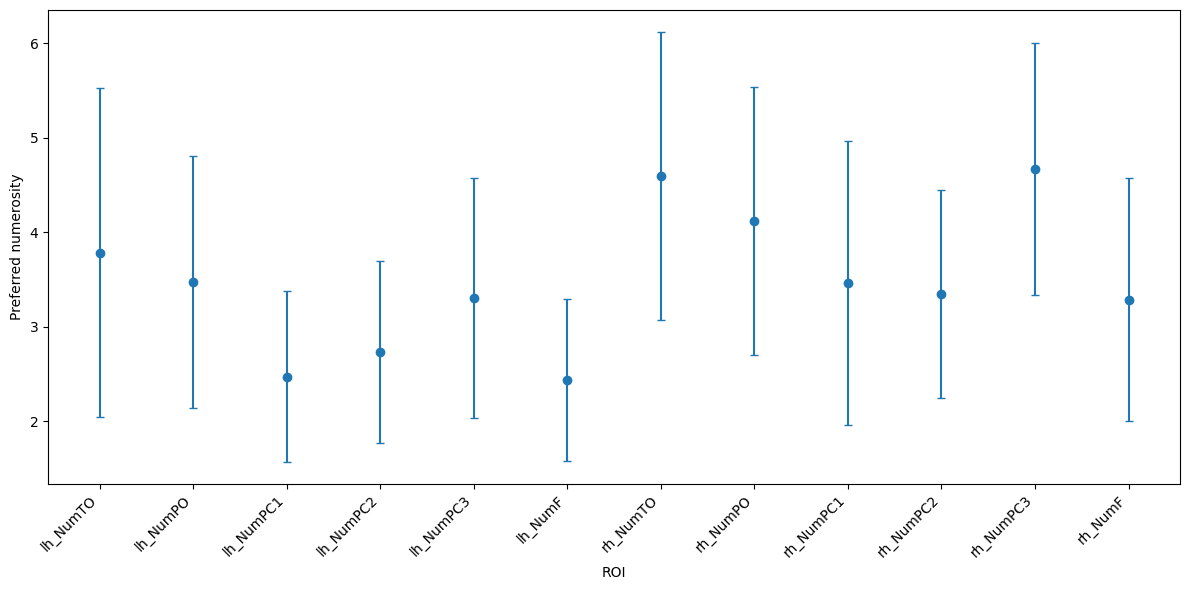

In [54]:
from prfmodel.plotting import plot_parameter_by_roi

plot_parameter_by_roi(
    params_valid,
    "numerosity",
    params_valid["roi"],
    order=roi_order,
    ylabel="Preferred numerosity"
)

# Improve figure formatting
ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")

plt.gcf().set_size_inches(12, 6)
plt.tight_layout()
plt.show()

The error bars show the standard deviation across vertices, not the standard error of the mean. Average preferred numerosity is highest in the occipital maps NumPO (parietal occipital) and NumTO (temporal occipital) and lowest in NumF (frontal), while the maps around the parietal cortex (NumPC1, NumPC2, NumPC3) sit close together in between.

However, the variation within each ROI is large relative to these differences, and the number of surviving vertices
differs strongly between maps.

We can also look at the average pRF size of each ROI.

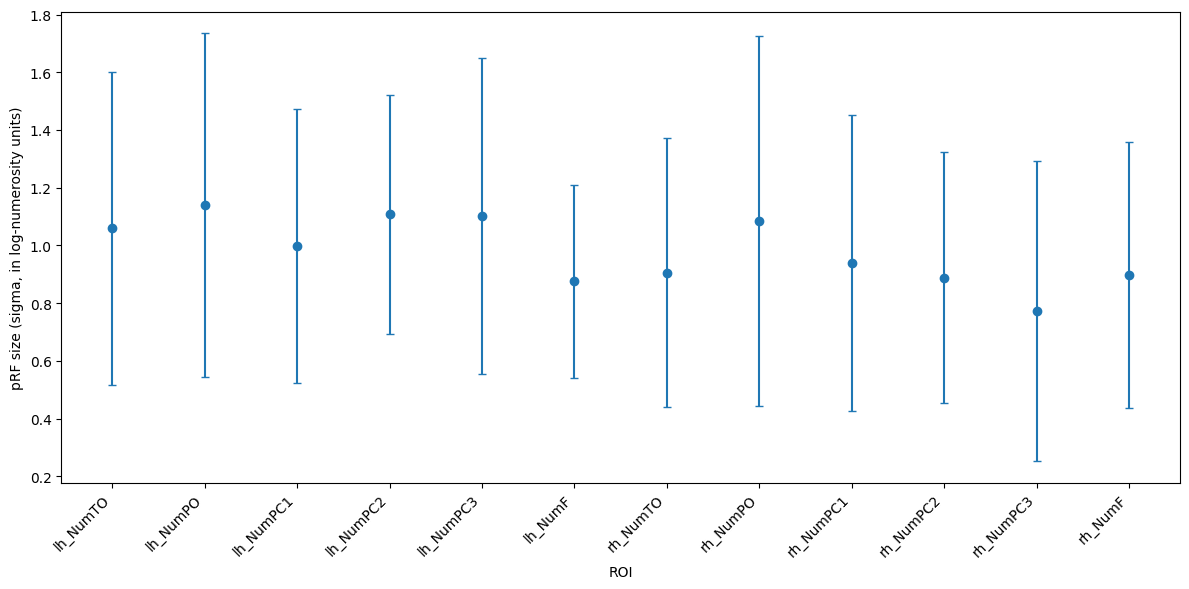

In [55]:
plot_parameter_by_roi(
    params_valid,
    "sigma",
    params_valid["roi"],
    order=roi_order,
    ylabel="pRF size (sigma, in log-numerosity units)",
)

# Improve figure formatting
ax = plt.gca()
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")

plt.gcf().set_size_inches(12, 6)
plt.tight_layout()
plt.show()

Average pRF size is roughly constant across the ROI's

## Visualizing preferred numerosity on the cortical surface

We can now visualize the preferred numerosity estimated by the pRF model on the cortical surface. We use the fitted `mu` parameters to obtain preferred numerosity on the natural scale, and project these values onto the left and right hemispheres.

Before plotting, we apply an R-squared threshold to exclude vertices where the model does not explain the observed responses sufficiently well. We also highlight the selected ROIs on the flatmaps, allowing us to examine the spatial distribution of numerosity preferences within these regions.

The visual ROI boundaries were defined using earlier programs and subsequently transformed into the coordinate space of the current surface representation. Because these transformations involve several steps, small differences in alignment between the ROI outlines and the surface may occur. The boundaries should therefore be interpreted as an anatomical reference rather than an exact delineation of the displayed vertices.

Here, we use an R-squared threshold of 0.2 just like before and plot NPC2 for the left and right hemispheres. 


Flatmap coverage
LH: 29,130 / 147,277
RH: 27,311 / 146,890


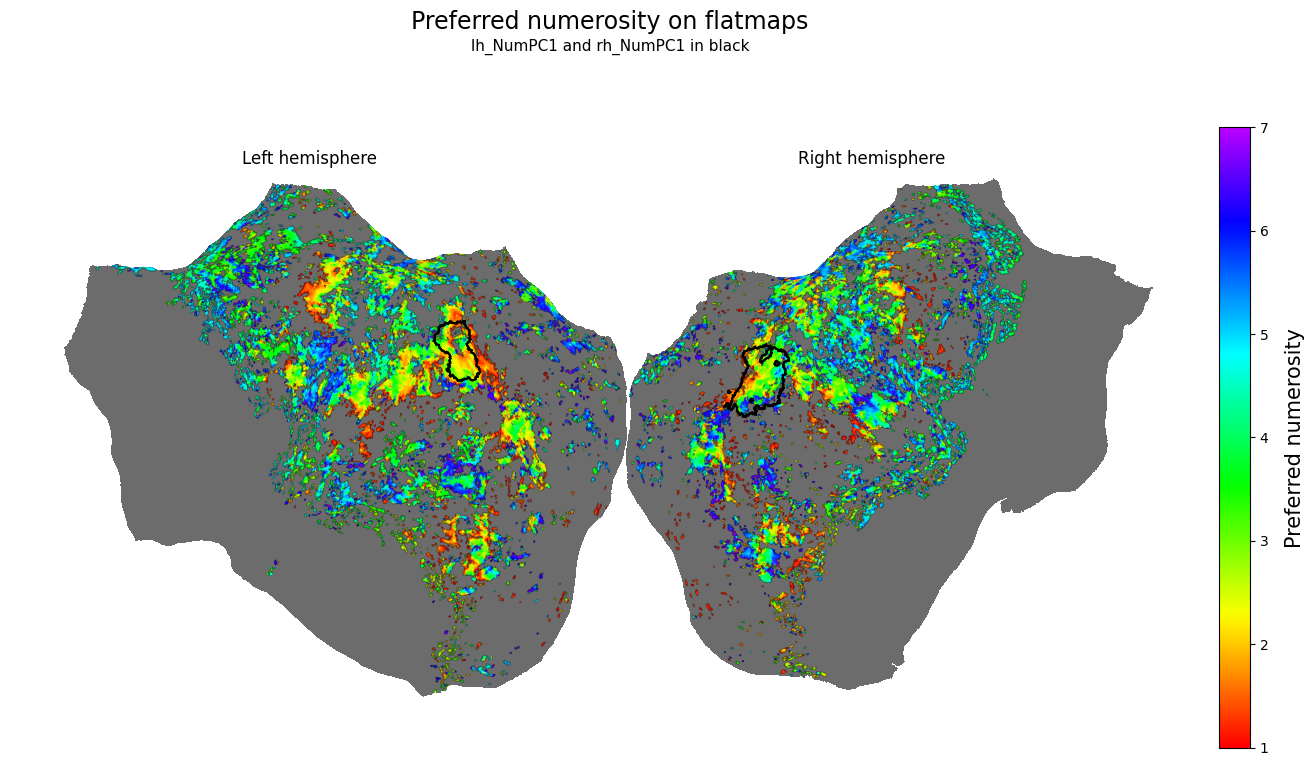

In [57]:
import importlib
import helpers

importlib.reload(helpers)
from helpers import plot_numerosity_flatmaps

surf_dir = PROJECT_ROOT / "data" / "s1" / "surf"
# pRF filtering
r2_threshold = 0.2
lh_roi_id = 3
rh_roi_id = 9

plot_numerosity_flatmaps(
    sgd_params=sgd_params,
    r_squared=r_squared,
    valid_vertex_indices=valid_vertex_indices,
    roi_ids=dataset.vertex_roi_index,
    roi_mapping = roi_mapping,
    surf_dir=surf_dir,
    lh_roi_id=lh_roi_id,
    rh_roi_id=rh_roi_id,
    r2_threshold=r2_threshold
    )
   

The flatmaps show the spatial distribution of preferred numerosity across the cortical surface. Only vertices passing the R-squared threshold are displayed.

## Analyzing numerosity preference across the cortical surface

So far, we have examined the estimated pRF parameters across different ROIs. We will now investigate how preferred numerosity changes with position within a single ROI.

To do this, we use the relative geodesic distance of each vertex within the selected ROI, which is stored in the dataset. This distance is defined relative to the pre-delineated low and high endpoints of the ROI, allowing us to compare how numerosity preference changes along the ROI. Geodesic distance measures distance along the cortical surface, rather than straight-line distance through three-dimensional space.

We first fit the pRF model separately for the four individual stimulus conditions: Area, Size, Dens, and Circ. We can then compare their estimated numerosity preferences with those obtained from the Average condition.

In [36]:
from helpers import fit_condition_roi

conditions = ["Area", "Size", "Dens", "Circ"]

roi_index = 7  # LH NumTO

condition_results = {}

for condition in conditions:
    condition_results[condition] = fit_condition_roi(
        dataset=dataset,
        condition=condition,
        prf_model=prf_model,
        stimulus=stimulus,
        param_ranges=param_ranges,
        convert_psc=convert_psc,
        roi_index=roi_index
    )


Fitting Area | ROI index 7
Valid voxels: 382,364
Valid ROI vertices: 1,653


Processing parameter grid:   0%|          | 0/123 [00:00<?, ?it/s]

Processing data batches:   0%|          | 0/9 [00:00<?, ?it/s]

Processing data batches:   0%|          | 0/1 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/1000 [00:00<?, ?it/s]


Fitting Size | ROI index 7
Valid voxels: 374,989
Valid ROI vertices: 1,653


... (10 outputs left out)

Processing parameter grid:   0%|          | 0/123 [00:00<?, ?it/s]

Processing data batches:   0%|          | 0/9 [00:00<?, ?it/s]

Processing data batches:   0%|          | 0/1 [00:00<?, ?it/s]

Optimizing batch:   0%|          | 0/1000 [00:00<?, ?it/s]

Before comparing the conditions, we prepare the fitted parameters in a consistent way.

For each vertex, we collect its preferred numerosity, pRF size (`sigma`), R-squared value, and geodesic distance from the ROI centroid. The fitted parameter `mu` is expressed in log-numerosity space, so we exponentiate it to obtain preferred numerosity on the natural scale.

We apply the same selection criteria to the Average and individual conditions:

- R-squared greater than 0.2.
- Preferred numerosity between 1 and 7.
- pRF size (`sigma`) smaller than 2.8.

We also restrict the Average results to vertices belonging to the selected ROI. The individual condition fits have already been restricted to that ROI.

The resulting datasets contain the filtered vertices and their corresponding distances and pRF parameters for each condition. The number of retained vertices can differ between conditions because the selection criteria are applied separately.

In [ ]:
import importlib
import helpers

importlib.reload(helpers)

from helpers import prepare_distance_data

# Analysis settings
roi_index = 7  # RH NumTO
r2_threshold = 0.3
num_min = 1
num_max = 7
sigma_max = 2.8

# Prepare Average and individual condition results
plot_data = prepare_distance_data(
    dataset=dataset,
    sgd_params=sgd_params,
    r_squared=r_squared,
    vertex_valid=vertex_valid,
    roi_index_valid=roi_index_valid,
    condition_results=condition_results,
    roi_index=roi_index,
    r2_threshold=r2_threshold,
    num_range=(num_min, num_max),
    sigma_max=sigma_max
)


We now group vertices into distance bins of 2 mm. For each bin, we calculate the mean preferred numerosity across all vertices within that bin, separately for each stimulus condition.

This allows us to examine how numerosity preference changes with distance from the ROI centroid.

For the Average condition, we additionally fit a logarithmic function to the binned means. To estimate uncertainty in this relationship, we use bootstrap resampling: vertices are sampled with replacement, the distance bins are recalculated, and the logarithmic function is refitted. We repeat this procedure 1,000 times.

The 2.5th and 97.5th percentiles of the resulting bootstrap curves define the 95% confidence interval.

In [38]:
from helpers import fit_distance_numerosity

# Analysis settings
bin_width = 2.0
n_bootstrap = 1000
random_seed = 22

# Run analysis
distance_results = fit_distance_numerosity(
    plot_data=plot_data,
    bin_width=bin_width,
    n_bootstrap=n_bootstrap,
    random_state=random_seed
)


Successful bootstrap fits: 1000 / 1000


Finally, we plot the binned preferred numerosity for all four individual stimulus conditions alongside the Average condition.

The Average condition is shown with error bars representing the standard error of the mean (SEM) within each distance bin. We also show the logarithmic fit and its 95% bootstrap confidence interval.

This visualization allows us to compare how preferred numerosity varies across the ROI for the different stimulus conditions, and to assess the overall spatial trend in the Average condition.

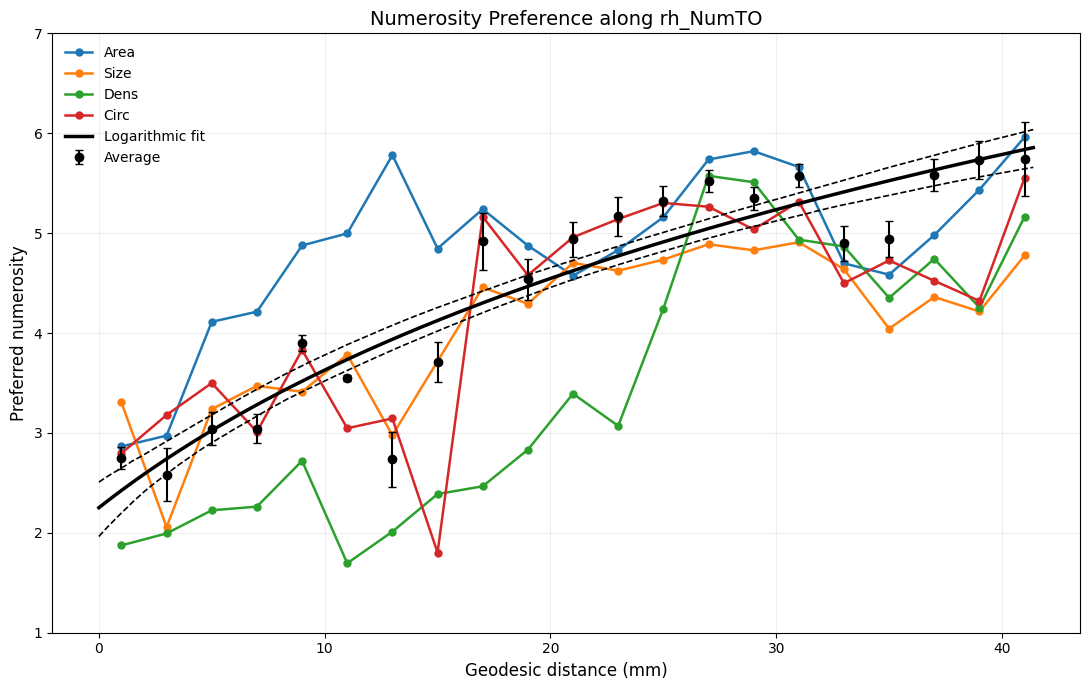

(<Figure size 1100x700 with 1 Axes>,
 <Axes: title={'center': 'Numerosity Preference along rh_NumTO'}, xlabel='Geodesic distance (mm)', ylabel='Preferred numerosity'>)

In [ ]:
from helpers import plot_distance_numerosity

roi_name = roi_mapping[roi_index]

plot_distance_numerosity(
    binned_data=distance_results["binned_data"],
    fit_params=distance_results["fit_params"],
    x_fit=distance_results["x_fit"],
    lower=distance_results["lower"],
    upper=distance_results["upper"],
    roi_name = roi_name
)

## Conclusion

This example showed how to fit a one-dimensional Gaussian pRF model to empirical fMRI data collected during a numerosity experiment. We started by exploring the stimulus and the measured BOLD responses, then projected the responses onto the cortical surface and prepared them for model fitting.

We defined a pRF model and optimized its parameters in three stages: a grid search to obtain initial estimates of `mu` and `sigma`, least squares to adjust the baseline and amplitude, and stochastic gradient descent to fine-tune the parameters. We then evaluated the model fit using R-squared and visualized the estimated pRF parameters across the cortical surface and between ROIs.

Finally, we fitted the model separately to the four individual stimulus conditions and investigated how preferred numerosity changes with relative geodesic distance within a selected ROI. By comparing the spatial organization of numerosity preferences across conditions that control for different visual properties, we can investigate whether the observed topographic organization is consistently related to numerosity rather than being driven by other stimulus features, such as dot size, total area, density, or circumference.

## References

Harvey, B. M., Klein, B. P., Petridou, N., & Dumoulin, S. O. (2013). Topographic representation of numerosity in the human parietal cortex. *Science*, *341*(6150), 1123–1126. https://doi.org/10.1126/science.1239052

Hendrikx, E., Paul, J. M., van Ackooij, M., van der Stoep, N., & Harvey, B. M. (2024). Cortical quantity representations of visual numerosity and timing overlap increasingly into superior cortices but remain distinct. *NeuroImage*, *286*, 120515. https://doi.org/10.1016/j.neuroimage.2024.120515